# Tópicos por período legal

Este notebook responde: **sobre o que falam os anúncios, e isso muda ao longo do século XIX?**
Usamos o modelo de tópicos `t5` (corpus `corp3`, campos `c5`), já gravado no banco compartilhado do grupo.
O modelo antigo `t4` (6 tópicos) aparece só na seção 8, para comparação.


Cada gráfico vem com uma ou duas frases dizendo o que ele mostra. Os números dessas frases foram lidos da saída
da própria execução; se o banco mudar, **confira os números de novo**.

> **Cuidado ao ler:** os anúncios foram achados por **frases de busca**, não por sorteio. O que aparece aqui descreve
> o que a busca encontrou, não todos os anúncios do século XIX. Os **nomes** dos tópicos são **hipóteses do grupo**, não fatos.

## 1. O que é um tópico e por que k = 6
**Um tópico é um grupo de palavras que costumam aparecer juntas nos mesmos anúncios.** O programa (LDA) não lê o sentido:
ele só agrupa palavras. Quem dá nome ao grupo somos nós, olhando as palavras e os anúncios.

**Por que 6 tópicos (k = 6)?** Rodamos o modelo várias vezes com sementes diferentes (ver `scripts/estabilidade_topicos.py`)
e medimos quantos tópicos **se repetem** (similaridade de cosseno ≥ 0,8). Com k = 4, 56% dos tópicos se repetem; com k = 6, 59%;
com k = 8, 50%; com k = 10, 29%; com k = 12, 44%. Não cai de forma regular, mas k = 10 é o pior. Mantemos k = 6 (e não k = 4) para separar mais temas. Mesmo em k = 8, quatro temas se repetem muito bem nas
sementes: fuga (0,93), serviço doméstico (0,90), ama de leite (0,85) e aluguel de homens (0,81).
**O resultado também depende da semente do sorteio:** com uma semente fixa, 3 anúncios a mais já reorganizaram todos os tópicos. Por isso usamos a semente mais representativa entre 10.
Ou seja, a estabilidade é **moderada**: os resultados abaixo são pistas, não medidas exatas.

## Preparação: ler o banco
O banco devolve no máximo 1000 linhas por consulta, então lemos em blocos (paginação).

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from hdb import config
from hdb.banco import BancoSupabase

pd.set_option("display.max_colwidth", 200)
pd.set_option("display.width", 200)
db = BancoSupabase().cliente      # lê o config/.env pelo módulo hdb

def ler_tudo(consulta, bloco=1000):
    """Executa a consulta em blocos de 1000 linhas e junta o resultado."""
    linhas, inicio = [], 0
    while True:
        parte = consulta().range(inicio, inicio + bloco - 1).execute().data
        linhas += parte
        if len(parte) < bloco:
            return pd.DataFrame(linhas)
        inicio += bloco

MODELO = config.VERSAO_TOPICOS
COMPARA = "t4"
palavras = ler_tudo(lambda: db.table("topico_palavras").select("versao,topico,palavra,peso")
                    .in_("versao", [MODELO, COMPARA]).order("versao").order("topico").order("peso", desc=True))
dist = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao")
                .eq("versao", MODELO).order("anuncio_id").order("topico"))
anuncios = ler_tudo(lambda: db.table("anuncios_completos")
                    .select("id,periodo_legal,c_tipo,c_sexo,c_idade_min,c_idade_max,ano,texto")
                    .in_("versao", list(config.VERSOES_ANUNCIOS)).eq("c_versao", config.VERSAO_CAMPOS).order("id"))
print(f"{dist['anuncio_id'].nunique()} anúncios no modelo {MODELO}; {len(anuncios)} anúncios com campos {config.VERSAO_CAMPOS} no banco")

2167 anúncios no modelo t5; 32401 anúncios com campos c5 no banco


In [2]:
PERIODOS = ["antes de 1831", "1831–1850", "1850–1871", "1871–1888"]
def periodo_curto(p):
    return p if p.startswith("antes") else p.split(" ")[0]

# Nomes SUGERIDOS (hipóteses do grupo): o LDA numera os tópicos ao acaso, então hdb.topicos.nomear dá a cada tópico
# o nome (de topicos.REFERENCIAS) cujas palavras mais aparecem entre as suas 12 de maior peso.
from hdb.topicos import REFERENCIAS, nomear
NOMES = nomear({t: g.sort_values("peso", ascending=False)["palavra"].head(12) for t, g in palavras[palavras.versao == MODELO].groupby("topico")})
K = len(NOMES)
rot = lambda t: f"T{t} {NOMES[t]}"

# Uma linha por anúncio do modelo, com o tópico dominante
pivo = dist.pivot(index="anuncio_id", columns="topico", values="proporcao")
base = anuncios.drop_duplicates("id").set_index("id").join(pivo, how="inner")
base["dominante"] = base[list(range(K))].idxmax(axis=1)
base["periodo"] = pd.Categorical(base["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)
print(len(base), "anúncios na base de análise")
if len(base) != 2167:
    print(f"ATENÇÃO: os comentários deste caderno foram escritos para 2167 anúncios e agora são {len(base)}: "
          "confira os números dos textos antes de usar.")

# Paleta Okabe-Ito, uma cor por tópico
CORES = ["#0072B2", "#D55E00", "#E69F00", "#009E73", "#CC79A7", "#999999"]
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

2167 anúncios na base de análise


## 2. Os tópicos do modelo `t5`
Abaixo, as **12 palavras de maior peso** de cada tópico (as palavras estão sem acento, como no corpus padronizado).
A coluna **Nome sugerido** é uma **proposta provisória**: o grupo precisa confirmar ou trocar.

In [3]:
tab = (palavras[palavras["versao"] == MODELO].groupby("topico")["palavra"].apply(lambda s: ", ".join(s.head(12))))
tabela = pd.DataFrame({"Nome sugerido": [NOMES[t] for t in tab.index], "12 palavras de maior peso": tab.values},
                      index=pd.Index(tab.index, name="Tópico"))
tabela

,Nome sugerido,12 palavras de maior peso
Tópico,,
0,Venda com preço e qualidades,"vende, preto, anos, bom, cozinheiro, aluga, moleque, precisa, servico, boa, idade, perfeito"
1,Ama de leite,"aluga, leite, ama, preta, servico, bom, boa, meses, criancas, todo, carinhosa, parda"
2,Serviço doméstico (aluguel),"aluga, preta, lava, servico, cozinha, todo, engoma, lavar, faz, engomar, cozinhar, preto"
3,Fuga: roupa levada e nação,"dia, nome, fugiu, anos, sera, levar, idade, corrente, bem, escravo, preto, levou"
4,Venda de moleques e pretos (lotes),"dois, vende, escravos, preta, pretos, precisa, vendem, anos, fora, idade, moleques, bem"
5,"Fuga: nome, idade e dono","nome, fugiu, nacao, dia, corrente, escravo, preto, alvicaras, idade, recebera, anos, dele"


**Nomes sugeridos (provisórios), dados pelas palavras de cada tópico; o número do tópico muda a cada rodada, o nome acompanha o conteúdo.** Dois tópicos são **fuga** e juntos têm 418 dos 433 anúncios de fuga (96%): **roupa levada e nação** (`fugiu`, `levou`, `nacao`, `levar`, `corrente`: 238 fugas) e **nome, idade e dono**, que na prática é a **fórmula mais antiga** (`alviçaras`, `recebera`, `dele`, `nome`, `escravo`: 180 fugas; é o tema de maior peso antes de 1831, 34,0%). **Ama de leite** (`leite`, `ama`, `meses`, `carinhosa`, `criancas`) tem 189 das 234 amas de leite (81%). **Serviço doméstico (aluguel)** (`aluga`, `lava`, `cozinha`, `engoma`, `servico`) reúne 403 dos 846 aluguéis. **Venda com preço e qualidades** (`vende`, `perfeito`, `cozinheiro`, `moleque`, `idade`) tem 352 das 618 vendas, e **venda de moleques e pretos (lotes)** (`dois`, `vendem`, `escravos`, `pretos`) é o mais fraco e misto (179 anúncios: venda, aluguel e compra).

## 3. Os 3 anúncios mais típicos de cada tópico
São os 3 com **maior proporção** daquele tópico. Mostramos os primeiros 250 caracteres do texto original.
Serve para conferir se o nome sugerido faz sentido.

In [4]:
for t in range(K):
    print(f"=== Tópico {t}: {NOMES[t]} ===")
    top3 = base.sort_values(t, ascending=False).head(3)
    for i, r in top3.iterrows():
        txt = " ".join(str(r["texto"]).split())[:250]
        print(f"  [id {i}, {r['periodo']}, tipo {r['c_tipo']}, proporção {r[t]:.2f}] {txt}")
    print()

=== Tópico 0: Venda com preço e qualidades ===
  [id 33669, 1871–1888, tipo venda, proporção 0.98] VESDESE una cas é terreno, tendo este Gra E-SE um escravo, boa figura e moço, o qual ças de frente, sendo este proprio, com agua do padaria é é melio bom para ostro caniammento e tanque para lavar « Bicas correntes como pagem, porque entende de - em 
  [id 38277, 1831–1850, tipo venda, proporção 0.98] VENDE-SE hum preto de nação Caçange , idade de 18 annos, peritimo official de Pedreiro; na qua do Ouvidor n. 178. MUDANÇA DE CASA. TIHOMAZ Gosling aproveita esta occasião para agradecer ao respeitavel publico, a preferencia e protecção que recebeu du
  [id 37793, antes de 1831, tipo venda, proporção 0.98] 10 “ No largo do Paço n. 16, vendem-se varios escravos Jadinos) séndo hum perfeito cosinheiro dé tóda a qualidade de commida, e de 18 annos de idade, bom page, e comeprador; e outro de 17 annos, cosinheiro do ordinario, pers feito page, menta bem a c

=== Tópico 1: Ama de leite ===
  [id 13

**Leitura dos exemplos** (3 por tópico, os mais típicos). Combinam com o nome: as fugas de roupa e nação (ids 29280, 33752, 22189), a ama de leite (ids 13851, 13886), o serviço doméstico (ids 11549, 10836), as vendas de lotes e de pretos com ofício (ids 38277, 37793, 22477). **Discordâncias:** (a) um dos três típicos de venda (id 33669) é a venda de **uma casa e um terreno** que cita um escravo, anúncio colado; (b) um dos típicos da fuga mais antiga (id 6845) é um **anúncio de almanaque** com uma fuga verdadeira colada no fim, que a regra não consegue separar; (c) um dos típicos do serviço doméstico (id 33636) é "uma criada de cor", em que não dá para saber se a pessoa era escravizada. **Auditoria mais ampla:** li os 10 anúncios mais típicos de cada tópico em duas rodadas (rótulos de Claude). Na segunda, em anúncios que as regras não tinham visto, **6 de 52 (11,5%) ainda eram problema**: um anúncio de rapé, um cavalo escrito "cavalio", um extrato policial de presos, uma cópia de decreto, uma venda de engenho e uma máquina colada à frente de um anúncio de pessoa. A meta de no máximo 2 em 30 **não foi atingida**; o lixo que sobra é de muitos tipos pequenos (cauda longa), e cada rodada de ajuste acha outros. As regras para decreto, extrato, fumo e "cavalio" foram acrescentadas **depois** dessa medida e **não foram medidas em anúncios novos**.

## 4. Peso de cada tópico por período legal
Para cada período, a **proporção média** de cada tópico nos anúncios daquele período (cada coluna soma 100%).

               T0 Venda com preço e qualidades  T1 Ama de leite  T2 Serviço doméstico (aluguel)  T3 Fuga: roupa levada e nação  T4 Venda de moleques e pretos (lotes)  T5 Fuga: nome, idade e dono     n
periodo                                                                                                                                                                                                 
antes de 1831                             13.6             21.3                             9.4                           11.3                                   10.5                         34.0   152
1831–1850                                 28.0             16.8                            18.1                           11.1                                   13.6                         12.3   565
1850–1871                                 25.1             19.7                            26.8                           11.8                                    8.5                          8.1  

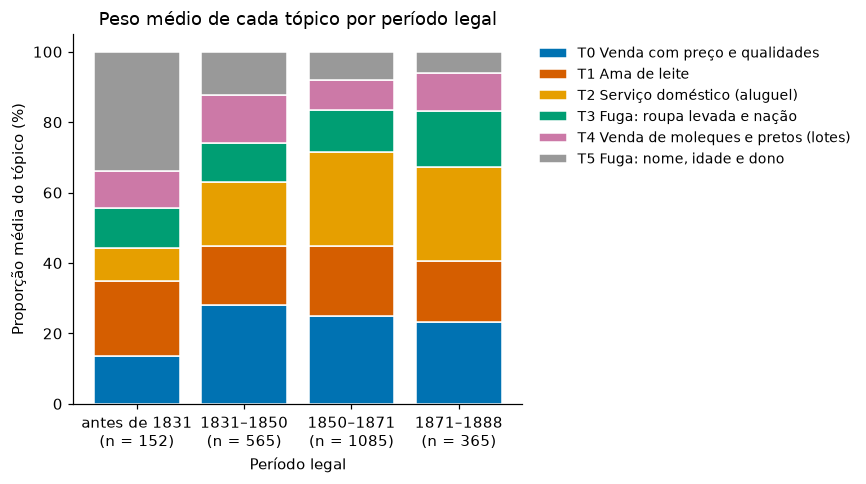

In [5]:
media = base.groupby("periodo", observed=True)[list(range(K))].mean().reindex(PERIODOS)
n_per = base.groupby("periodo", observed=True).size().reindex(PERIODOS)
med = (media * 100).round(1)
med.columns = [rot(t) for t in med.columns]
print(med.assign(n=n_per).to_string())
print("\nComposição por tipo em cada período (% dos anúncios):")
print((pd.crosstab(base["periodo"], base["c_tipo"], normalize="index") * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
fundo = np.zeros(len(PERIODOS))
for t in range(K):
    ax.bar(range(len(PERIODOS)), media[t].values * 100, bottom=fundo, color=CORES[t], edgecolor="white", label=rot(t))
    fundo += media[t].values * 100
ax.set_xticks(range(len(PERIODOS)))
ax.set_xticklabels([f"{p}\n(n = {n_per[p]})" for p in PERIODOS])
ax.set_title("Peso médio de cada tópico por período legal")
ax.set_xlabel("Período legal"); ax.set_ylabel("Proporção média do tópico (%)")
ax.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9)
fig.tight_layout(); plt.show()

**O que se vê:** os dois tópicos de **fuga somados** caem de 45,3% antes de 1831 para 23,4% em 1831–1850, 19,9% em 1850–1871 e 22,2% em 1871–1888. A fuga mais antiga (fórmula "alviçaras") despenca de 34,0% para 6,2%, e a de roupa e nação sobe um pouco no fim (de 11,1% a 16,0%). O **serviço doméstico (aluguel)** **cresce até 1850–1871**: 9,4%, 18,1%, 26,8% e 26,7%. **Venda com preço e qualidades** vai de 13,6% a 28,0% (1831–1850) e fica em 25,1% e 23,2%. **Ama de leite** varia pouco (de 16,8% a 21,3%). **Cuidado:** a composição por tipo muda muito: fuga é 44,7% do corpus antes de 1831 e 21,6% em 1871–1888 (era 16,4% em 1850–1871), enquanto aluguel vai de 11,8% a 28,1%, 45,5% e 47,9%. Como o tópico acompanha o tipo (seção 7), parte do que parece mudança nos temas vem de **quantos anúncios de cada tipo a busca achou** em cada período. A fuga em 1871–1888 é maior que em 1850–1871 por causa das páginas de cobertura dos anos 1880, e não por mais fugas na época.

## 5. Por sexo
Aqui o tópico entra como **proporção média** entre os anúncios de cada sexo (`f` ou `m`).

> **Ressalva:** o sexo vem de **palavras do anúncio** ("preta", "preto", "moleque"…), e o tipo "ama de leite" é feminino
> **por construção**. Por isso, depois do gráfico, cruzamos **tipo × sexo** e **tipo × tópico** para separar o que
> é efeito do tipo.

{'Feminino': 1056, 'Masculino': 848}
c_sexo                                 Feminino  Masculino
T0 Venda com preço e qualidades            12.6       39.7
T1 Ama de leite                            30.7        6.4
T2 Serviço doméstico (aluguel)             35.2        9.9
T3 Fuga: roupa levada e nação               6.2       17.6
T4 Venda de moleques e pretos (lotes)      10.7       10.1
T5 Fuga: nome, idade e dono                 4.5       16.3


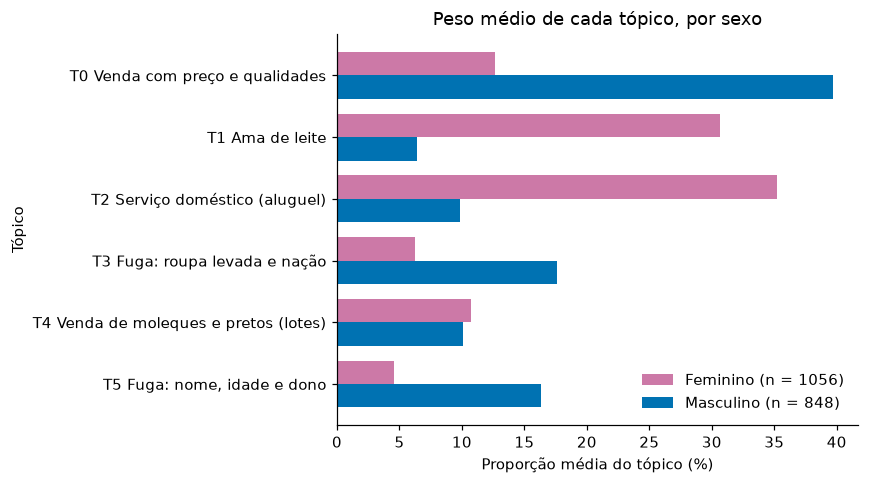

In [6]:
sx = base[base["c_sexo"].isin(["f", "m"])]
n_sx = sx.groupby("c_sexo").size()
m_sx = sx.groupby("c_sexo")[list(range(K))].mean().T * 100
m_sx.index = [rot(t) for t in m_sx.index]
m_sx = m_sx.rename(columns={"f": "Feminino", "m": "Masculino"})
print((n_sx.rename({"f": "Feminino", "m": "Masculino"})).to_dict())
print(m_sx.round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
y = np.arange(K); h = 0.38
ax.barh(y - h/2, m_sx["Feminino"].values, h, color="#CC79A7", label=f"Feminino (n = {n_sx.get('f', 0)})")
ax.barh(y + h/2, m_sx["Masculino"].values, h, color="#0072B2", label=f"Masculino (n = {n_sx.get('m', 0)})")
ax.set_yticks(y); ax.set_yticklabels(m_sx.index); ax.invert_yaxis()
ax.set_title("Peso médio de cada tópico, por sexo"); ax.set_xlabel("Proporção média do tópico (%)"); ax.set_ylabel("Tópico")
ax.legend(frameon=False)
fig.tight_layout(); plt.show()

In [7]:
# O sexo é efeito do tipo? Tipo x sexo (contagem) e tipo x tópico médio (%)
print(pd.crosstab(base["c_tipo"], base["c_sexo"].fillna("não diz")).to_string())
print()
por_tipo = base.groupby("c_tipo")[list(range(K))].mean() * 100
por_tipo.columns = [f"T{t}" for t in por_tipo.columns]
print(por_tipo.round(1).assign(n=base.groupby("c_tipo").size()).to_string())
print()
# Dentro de um mesmo tipo, f e m diferem? (fuga e venda são os tipos com os dois sexos)
for tipo in ["fuga", "venda"]:
    s = sx[sx["c_tipo"] == tipo]
    if s["c_sexo"].nunique() == 2:
        d = (s.groupby("c_sexo")[list(range(K))].mean() * 100).round(1)
        d.columns = [f"T{t}" for t in d.columns]
        print(f"Tipo {tipo}: n =", s.groupby("c_sexo").size().to_dict()); print(d.to_string()); print()

c_sexo        ambos    f    m  não diz
c_tipo                                
aluguel          47  504  295        0
ama_de_leite     21  206    5        2
compra            7   13   16        0
fuga             17   68  263       85
venda            83  265  269        1

                T0    T1    T2    T3    T4    T5    n
c_tipo                                               
aluguel       22.5  20.2  40.6   2.9   9.9   3.9  846
ama_de_leite   8.8  70.1   8.2   2.9   6.8   3.2  234
compra        19.6  14.7  15.4   6.3  39.8   4.3   36
fuga           3.7   2.0   2.9  49.3   4.1  38.1  433
venda         48.9   9.0  20.1   3.2  14.9   3.9  618

Tipo fuga: n = {'f': 68, 'm': 263}
         T0   T1   T2    T3   T4    T5
c_sexo                                
f       2.4  3.2  3.4  58.5  5.0  27.5
m       4.1  1.4  2.1  48.6  3.6  40.3

Tipo venda: n = {'f': 265, 'm': 269}
          T0    T1    T2   T3    T4   T5
c_sexo                                  
f       31.6  13.6  33.2  2.3  16.0 

**O que se vê:** entre mulheres (n = 1.056) pesam mais o serviço doméstico (35,2%) e a ama de leite (30,7%); entre homens (n = 848) pesa a venda com preço e qualidades (39,7%). **Em parte é efeito do tipo:** quase todo anúncio de ama de leite é feminino (206 `f` contra 5 `m`) e a fuga é majoritariamente masculina (263 `m` contra 68 `f`). Dentro da **fuga** a diferença é pequena: nas mulheres o tema de roupa e nação pesa 58,5% e nos homens 48,6%. Já dentro da **venda** ela **permanece**: nas mulheres os temas se dividem entre venda com preço e qualidades (31,6%) e serviço doméstico (33,2%); nos homens a venda com preço e qualidades chega a 65,3% e o serviço doméstico fica em 6,7%. Ou seja, na venda os anúncios de mulheres falam de serviço doméstico e os de homens de preço e qualidades. Com n de 265 e 269, é um sinal razoável, mas ainda uma **pista**.

## 6. Por faixa de idade
Só entram anúncios que **dizem a idade** (usamos o ponto médio quando há intervalo). O número é pequeno,
então **as diferenças entre faixas são frágeis**: veja o `n` de cada linha antes de tirar conclusões.

In [8]:
base["idade"] = base[["c_idade_min", "c_idade_max"]].astype(float).mean(axis=1)
FAIXAS = ["até 12", "13–20", "21–35", "36+"]
base["faixa"] = pd.cut(base["idade"], bins=[-1, 12, 20, 35, 200], labels=FAIXAS)
com_idade = base[base["idade"].notna()]
print(f"{len(com_idade)} de {len(base)} anúncios têm idade")
ti = com_idade.groupby("faixa", observed=True)[list(range(K))].mean() * 100
ti.columns = [f"T{t}" for t in ti.columns]
ti.insert(0, "n", com_idade.groupby("faixa", observed=True).size())
ti.round(1)

356 de 2167 anúncios têm idade


,n,T0,T1,T2,T3,T4,T5
faixa,,,,,,,
até 12,39,51.3,10.7,8.8,9.4,14.0,5.8
13–20,186,41.7,8.0,14.0,13.3,11.6,11.4
21–35,91,26.0,7.3,8.2,34.7,6.7,17.1
36+,40,27.3,7.2,9.1,28.8,6.2,21.5


**Fragilidade:** só 356 dos 2.167 anúncios dizem a idade, e as faixas têm n = 39, 186, 91 e 40. Os tópicos de **fuga** somados pesam 15,2% até 12 anos, 24,7% de 13 a 20, **51,8% de 21 a 35** e 50,3% de 36 em diante: **quem tem idade registrada na fuga é, em geral, adulto**. **Crianças** aparecem sobretudo em venda: até 12 anos, a venda com preço e qualidades pesa 51,3%, e de 13 a 20 anos, 41,7%. São diferenças frágeis: a idade só aparece quando o OCR a leu e a faixa até 12 anos tem 39 anúncios.

## 7. Tópico × tipo de anúncio
Cada anúncio vai para o seu **tópico dominante** (o de maior proporção). A matriz conta quantos anúncios de cada tipo
caem em cada tópico. Se cada tópico fosse "só" um tipo, haveria um bloco forte por coluna.

               T0   T1   T2   T3   T4   T5  Total
c_tipo                                           
aluguel       194  167  403    4   62   16    846
ama_de_leite   17  189   14    1   10    3    234
compra          9    6    3    2   16    0     36
fuga            5    2    2  238    6  180    433
venda         352   40  123    6   85   12    618
Total         577  404  545  251  179  211   2167


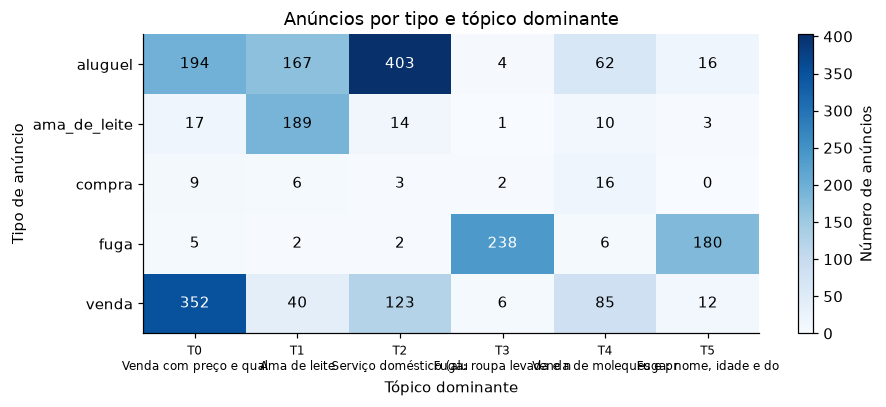

In [9]:
tt = pd.crosstab(base["c_tipo"], base["dominante"])
tt.columns = [f"T{t}" for t in tt.columns]
tt["Total"] = tt.sum(axis=1)
tt.loc["Total"] = tt.sum()
print(tt.to_string())

mat = pd.crosstab(base["c_tipo"], base["dominante"]).reindex(columns=range(K), fill_value=0)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
im = ax.imshow(mat.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(K)); ax.set_xticklabels([f"T{t}\n{NOMES[t][:22]}" for t in range(K)], fontsize=8)
ax.set_yticks(range(len(mat))); ax.set_yticklabels(mat.index)
for i in range(mat.shape[0]):
    for j in range(K):
        v = mat.values[i, j]
        ax.text(j, i, str(v), ha="center", va="center", color="white" if v > mat.values.max() * 0.5 else "black")
ax.set_title("Anúncios por tipo e tópico dominante"); ax.set_xlabel("Tópico dominante"); ax.set_ylabel("Tipo de anúncio")
fig.colorbar(im, ax=ax, label="Número de anúncios")
fig.tight_layout(); plt.show()

**O que se vê:** os tópicos **acompanham bastante o tipo**: 418 dos 433 anúncios de fuga (96%) estão nos dois tópicos de fuga; 189 das 234 amas de leite no de ama de leite (81%); 403 dos 846 aluguéis no de serviço doméstico (48%), 194 em venda com preço e qualidades e 167 em ama de leite; e a venda se divide entre venda com preço e qualidades (352), serviço doméstico (123) e lotes (85). Então, em boa medida, os tópicos **são os tipos** (o modelo não descobriu muito além do que a classificação já dizia). O que os tópicos acrescentam está nas **palavras**: a fuga se divide entre uma fórmula antiga ("alviçaras") e a descrição da roupa e da nação, e o serviço doméstico atravessa aluguel e venda.

## 8. Comparação com o modelo `t4`
Para cada tópico de `t4`, buscamos o tópico de `t5` mais parecido pela **similaridade de cosseno** entre as distribuições de palavras.

> **Aproximação:** o banco guarda só as **12 palavras de maior peso** de cada tópico. Usamos a união dessas palavras
> como vocabulário e **peso 0** para as ausentes. O resultado é aproximado e ignora a cauda de cada tópico.

In [10]:
pal = palavras.pivot_table(index=["versao", "topico"], columns="palavra", values="peso", fill_value=0)
M2, M3 = pal.loc[COMPARA], pal.loc[MODELO]
vocab = sorted(set(M2.columns) | set(M3.columns))
A = M2.reindex(columns=vocab, fill_value=0).values
B = M3.reindex(columns=vocab, fill_value=0).values
cos = (A / np.linalg.norm(A, axis=1, keepdims=True)) @ (B / np.linalg.norm(B, axis=1, keepdims=True)).T
linhas = []
for i, antigo in enumerate(M2.index):
    j = int(cos[i].argmax())
    linhas.append({"Tópico do modelo antigo": antigo, "Palavras do modelo antigo": ", ".join(palavras[(palavras.versao == COMPARA) & (palavras.topico == antigo)]["palavra"].head(6)) + "…",
                   "Mais parecido no modelo novo": f"T{M3.index[j]} {NOMES[M3.index[j]]}", "Cosseno": round(float(cos[i, j]), 2)})
pd.DataFrame(linhas).set_index("Tópico do modelo antigo")

,Palavras do modelo antigo,Mais parecido no modelo novo,Cosseno
Tópico do modelo antigo,,,
0,"dia, fugiu, nome, corrente, nacao, levar…",T3 Fuga: roupa levada e nação,0.93
1,"preto, vende, bom, anos, aluga, cozinheiro…",T0 Venda com preço e qualidades,0.95
2,"aluga, preta, leite, ama, servico, precisa…",T1 Ama de leite,0.90
3,"escravo, rio, queira, dias, cidade, fugido…","T5 Fuga: nome, idade e dono",0.23
4,"anos, vende, moleque, idade, senhora, qualquer…",T0 Venda com preço e qualidades,0.62
5,"preta, lava, aluga, cozinha, engoma, vende…",T2 Serviço doméstico (aluguel),0.88


**O que se vê:** os temas claros do modelo antigo (`t4`, antes da limpeza) têm par no novo com cosseno alto: fuga com o de roupa e nação em **0,93**, venda e aluguel de homens com venda com preço e qualidades em **0,95**, aluguel de mulheres e ama de leite com ama de leite em **0,90** e serviço doméstico com o de serviço doméstico em **0,88**. **O tópico fraco de avisos misturados do modelo antigo não tem par** (0,23, com a fuga de nome, idade e dono), e o de venda de moleques e colunas mistas casa só em **0,62**. Isso indica que **a limpeza removeu o ruído que formava esses tópicos**. A perplexidade (811, contra 946 no modelo antigo) não é uma comparação direta, porque o corpus mudou. É uma comparação **aproximada** (só 12 palavras por tópico).

## 9. E se os aluguéis duvidosos entrassem? (variante `t5i`)
O `aluguel_incerto` são anúncios de aluguel em que o texto **não diz** se a pessoa era escravizada ("precisa-se de uma criada").
Eles ficam fora do modelo principal. Aqui ajustamos o mesmo modelo **com** eles (`t5i`) e comparamos a parcela de cada tema por período.
Os temas recebem o nome pelo mesmo critério de palavras, então a comparação é pelo **nome**, não pelo número.

In [11]:
VARIANTE = MODELO + "i"
pal_i = ler_tudo(lambda: db.table("topico_palavras").select("versao,topico,palavra,peso").eq("versao", VARIANTE)
                 .order("topico").order("peso", desc=True))
dist_i = ler_tudo(lambda: db.table("anuncio_topicos").select("anuncio_id,topico,proporcao").eq("versao", VARIANTE)
                  .order("anuncio_id").order("topico"))
nomes_i = nomear({t: g.sort_values("peso", ascending=False)["palavra"].head(12) for t, g in pal_i.groupby("topico")})
pivo_i = dist_i.pivot(index="anuncio_id", columns="topico", values="proporcao").rename(columns=nomes_i)
com_i = anuncios.drop_duplicates("id").set_index("id")[["periodo_legal"]].join(pivo_i, how="inner")
com_i["periodo"] = pd.Categorical(com_i["periodo_legal"].map(periodo_curto), categories=PERIODOS, ordered=True)
sem = base[list(range(K))].rename(columns=NOMES).assign(periodo=base["periodo"])
media_sem = (sem.groupby("periodo", observed=True).mean() * 100).round(1).reindex(PERIODOS)
media_com = (com_i.groupby("periodo", observed=True)[list(pivo_i.columns)].mean() * 100).round(1).reindex(PERIODOS)
tab = pd.concat({"sem os duvidosos (t5)": media_sem, "com os duvidosos (t5i)": media_com}, axis=1)
print(f"{len(sem)} anúncios sem e {len(com_i)} com os aluguéis duvidosos (proporção média de cada tema por período, %)")
tab.T

2167 anúncios sem e 2341 com os aluguéis duvidosos (proporção média de cada tema por período, %)


periodo                                                              antes de 1831  1831–1850  1850–1871  1871–1888
sem os duvidosos (t5)  Venda com preço e qualidades                           13.6       28.0       25.1       23.2
                       Ama de leite                                           21.3       16.8       19.7       17.2
                       Serviço doméstico (aluguel)                             9.4       18.1       26.8       26.7
                       Fuga: roupa levada e nação                             11.3       11.1       11.8       16.0
                       Venda de moleques e pretos (lotes)                     10.5       13.6        8.5       10.7
                       Fuga: nome, idade e dono                               34.0       12.3        8.1        6.2
com os duvidosos (t5i) Venda com preço e qualidades                            7.9       12.1       23.0       24.2
                       Venda de mulheres (lavar, engomar, cozinhar)           14.2       19.0       16.8       18.0
                       Venda de moleques e pretos (lotes)                     15.7       26.3       19.1       17.2
                       Serviço doméstico (aluguel)                            17.2       18.2       21.7       19.7
                       Fuga: nome, idade e dono                                8.4        6.9        6.7       10.3
                       Fuga: roupa levada e nação                             36.7       17.4       12.6       10.6

**O que se vê:** com os aluguéis duvidosos o corpus passa de 2.167 para 2.341 anúncios (+174). O modelo escolhe **uma divisão diferente** (aparece um tema de venda de mulheres e some o de ama de leite), então a comparação por nome é parcial. **A queda da fuga se mantém:** somando os dois temas de fuga, 45,1% antes de 1831, 24,3%, 19,3% e 20,9%, quase igual ao modelo principal (45,3%, 23,4%, 19,9% e 22,2%). **O serviço doméstico já não é tão claro:** sem os duvidosos ele sobe de 9,4% a 26,7%; com eles vai de 17,2% a 21,7% e recua a 19,7%. Os aluguéis duvidosos ("criadas", "raparigas") são justamente serviço doméstico, então **decidir se eles entram muda a conclusão sobre o serviço doméstico**, e não só os níveis. Essa é a decisão do grupo mais importante para a apresentação.

## 10. O que os resultados dizem e o que não dizem

**O que sustenta (com as ressalvas abaixo):**

- Os tópicos de **fuga somados caem** de 45,3% antes de 1831 para 22,2% em 1871–1888 (seção 4), e a queda aparece também com os aluguéis duvidosos (seção 9) e com períodos do mesmo tamanho (caderno `equilibrio_periodos`). **Mas** a fuga também cai de 44,7% para 21,6% dos anúncios do corpus, então o tópico pode só refletir isso.
- O tópico de **serviço doméstico (aluguel)** cresce de 9,4% antes de 1831 a 26,7% em 1871–1888, e também com períodos iguais (de 13,5% a 27,6%). **Mas depende de os aluguéis duvidosos ficarem de fora**: com eles, o tema é quase estável a partir de 1850 (seção 9).
- Na **venda**, os anúncios de mulheres puxam o serviço doméstico e os de homens a venda com preço e qualidades (seção 5).
- Os temas de **fuga, ama de leite e serviço doméstico** reaparecem entre o modelo antigo e o novo (cosseno de 0,88 a 0,95) e nos exemplos lidos (seções 3 e 8).

**O que NÃO dizem:**

- **Não é amostra da população.** Os anúncios vêm de **frases de busca**; mudanças entre períodos podem refletir **o que a busca achou** (a composição por tipo muda), não o que se anunciava de fato.
- **Desigualdade entre períodos:** 2.167 anúncios (152, 565, 1.085 e 365 por período). O período 1871–1888 não tem nada de **1887 e 1888** e quase nada de 1886, então **ainda não dá para falar da Lei Áurea**.
- **Estabilidade moderada:** só 57% dos tópicos se repetem com k = 6 (k = 4 repete 61%). E o resultado **muda com poucos anúncios a mais ou a menos**: nesta mesma rodada de limpeza, a estabilidade de k = 6 foi de 54% a 39% e voltou a 57% conforme o corpus mudava em poucas unidades. Por isso o modelo usa a semente mais representativa de 10. Tratar os números como pistas, não medidas.
- **Os tópicos seguem em grande parte os tipos** (seção 7), então "tópico por período" é em boa medida "tipo por período".
- **Ainda há ruído** (6 de 52 anúncios típicos com problema na segunda auditoria) e colunas de classificados coladas.
- **Sexo e idade:** parte da diferença por sexo vem do tipo (seção 5) e as de idade têm n de 39 a 186 (seção 6).
- **Os nomes são hipóteses do grupo**, escolhidas pelas palavras e pelos exemplos, não fatos.